#### Goal

Understand what gets scored: the 15 extreme indices, computed from the true daily fields with the official code (src/indices_xclim.py).
1. How do the indices change with warming?
2. Which are hard to predict? Wny?
3. How sensitive are they to errors in the daily fields? This matters most for building your model.

The 15 indices are:

| # | Index | Name | Definition (as implemented in `src/indices_xclim.py`) | Variable | Frequency | Units | Needs 1961–1990 baseline |
|---|---|---|---|---|---|---|---|
| 1 | **FD** | Frost days | Number of days with tasmin < 0 °C | tasmin | yearly | days | |
| 2 | **SU** | Summer days | Number of days with tasmax > 25 °C | tasmax | yearly | days | |
| 3 | **ID** | Ice days | Number of days with tasmax < 0 °C | tasmax | yearly | days | |
| 4 | **TR** | Tropical nights | Number of days with tasmin > 20 °C | tasmin | yearly | days | |
| 5 | **GSL** | Growing season length | Length of the growing season, based on tas > 5 °C | tas | yearly | days | |
| 6 | **TXx** | Hottest day | Maximum of daily tasmax | tasmax | monthly | K | |
| 7 | **TNn** | Coldest night | Minimum of daily tasmin | tasmin | monthly | K | |
| 8 | **WSDI** | Warm spell duration index | Number of days in spells of ≥ 6 consecutive days with tasmax above its 90th percentile (day-of-year percentile, 5-day window, 1961–1990) | tasmax | yearly | days | ✅ |
| 9 | **CSDI** | Cold spell duration index | Number of days in spells of ≥ 6 consecutive days with tasmin below its 10th percentile (day-of-year percentile, 5-day window, 1961–1990) | tasmin | yearly | days | ✅ |
| 10 | **Rx5day** | Max 5-day precipitation | Maximum precipitation total over 5 consecutive days | pr | monthly | mm | |
| 11 | **CDD** | Consecutive dry days | Longest run of days with pr < 1 mm/day | pr | yearly | days | |
| 12 | **CWD** | Consecutive wet days | Longest run of days with pr ≥ 1 mm/day | pr | yearly | days | |
| 13 | **R95p** | Very wet day precipitation | Total precipitation on days with pr above its 95th percentile (day-of-year percentile, 5-day window, 1961–1990) | pr | yearly | mm | ✅ |
| 14 | **SDII** | Simple daily intensity index | Mean precipitation on wet days (pr ≥ 1 mm/day) | pr | yearly | mm/day | |
| 15 | **R10mm** | Heavy precipitation days | Number of days with pr ≥ 10 mm/day | pr | yearly | days | |

**Notes**
- **Groups:** 1–9 are temperature indices (absolute thresholds, extremes, percentile-based spells); 10–15 are precipitation indices (extremes, spells, intensity, frequency).
- **Frequency:** TXx, TNn and Rx5day are computed per month; the other 12 per year.
- **Baseline:** WSDI, CSDI and R95p compare each day with percentiles computed from the historical period 1961–1990 (the code's default `base_period`), so "hot" or "wet" means *relative to that period at the same time of year*.
- **Units:** precipitation is converted from kg m⁻² s⁻¹ to mm/day (× 86400) before the indices are computed; temperatures stay in K, with thresholds such as 0 °C written as 273.15 K.
- **Scoring rule:** these indices are computed from the predicted daily fields with this official code; index maps may not be predicted or corrected directly.

In [1]:
import os, sys, inspect
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"

from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

xr.set_options(use_bottleneck=False);   # accurate float32 reductions (notebook 02)

REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))
from src.indices_xclim import SELECTED_INDICES   # the official 15 indices

DATADIR = REPO_ROOT / "data" / "lite"
FILES = {
    "hist_1": "hist_train_1850_1931",
    "hist_2": "hist_train_1932_2014",
    "ssp126": "train_ssp126",
    "ssp370": "train_ssp370",
    "ssp585": "train_ssp585",
}

def open_file(key):
    """Open the ClimX file whose name ends with the suffix for `key`."""
    return xr.open_dataset(next(DATADIR.glob(f"*{FILES[key]}.nc")))

def global_mean(da):
    """Area-weighted (cos latitude) mean over lat and lon."""
    return da.weighted(np.cos(np.deg2rad(da.lat))).mean(("lat", "lon"))

TARGETS = ["tas", "tasmax", "tasmin", "pr"]     # the variables the indices use
SCENARIOS = ["ssp126", "ssp370", "ssp585"]
COLORS = {"historical": "#555555", "ssp126": "#2a78d6", "ssp370": "#eb6834", "ssp585": "#1baf7a"}
UNITS = {"FD": "days", "SU": "days", "ID": "days", "TR": "days", "GSL": "days",
        "TXx": "K", "TNn": "K", "WSDI": "days", "CSDI": "days", "Rx5day": "mm",
        "CDD": "days", "CWD": "days", "R95p": "mm", "SDII": "mm/day", "R10mm": "days"}

list(SELECTED_INDICES)

['FD',
 'SU',
 'ID',
 'TR',
 'GSL',
 'TXx',
 'TNn',
 'WSDI',
 'CSDI',
 'Rx5day',
 'CDD',
 'CWD',
 'R95p',
 'SDII',
 'R10mm']

#### The historical baseline (1961–1990)

WSDI, CSDI and R95p measure "hot" or "wet" relative to the this period.

In [2]:
with open_file("hist_2") as ds:
    baseline = ds[TARGETS].isel(forcing_scenario=0, drop=True).sel(time=slice("1961", "1990")).load()

baseline

<xarray.Dataset> Size: 38MB
Dimensions:  (time: 10950, lat: 12, lon: 18)
Coordinates:
  * lat      (lat) float64 96B -82.93 -67.85 -52.77 -37.7 ... 52.77 67.85 82.93
  * lon      (lon) float64 144B 9.375 29.38 49.38 69.38 ... 309.4 329.4 349.4
  * time     (time) object 88kB 1961-01-01 12:00:00 ... 1990-12-31 12:00:00
Data variables:
    tas      (time, lat, lon) float32 9MB 252.8 247.9 244.3 ... 234.4 237.0
    tasmax   (time, lat, lon) float32 9MB 253.9 249.7 246.4 ... 235.1 237.6
    tasmin   (time, lat, lon) float32 9MB 250.9 245.4 241.7 ... 233.9 236.6
    pr       (time, lat, lon) float32 9MB 2.118e-06 2.151e-06 ... 1.983e-06
Attributes: (12/49)
    Conventions:               CF-1.7 CMIP-6.2
    activity_id:               CMIP
    branch_method:             Hybrid-restart from year 1200-01-01 of piControl
    branch_time:               0.0
    branch_time_in_child:      0.0
    branch_time_in_parent:     438000.0
    ...                        ...
    table_id:                  day
    table_info:                Creation Date:(24 July 2019) MD5:0bb394a356ef9...
    title:                     NorESM2-MM output prepared for CMIP6
    tracking_id:               hdl:21.14100/15dfb832-4278-45d2-9234-f973ec264dcd
    variable_id:               huss
    variant_label:             r1i1p1f1

#### Compute all 15 indices, the same way evaluate() does

Question: what are each of these functions doing? What are being computed?

In [9]:
def load_daily(key):
    """
    Daily tas/tasmax/tasmin/pr data for one file, loaded into memory.
    """
    with open_file(key) as ds:
        return ds[TARGETS].isel(forcing_scenario=0, drop=True).load()

def compute_indices(daily, baseline):
    """All SELECTED_INDICES, passing the baseline only to the functions that need it."""
    out = {}
    for name, func in SELECTED_INDICES.items():
        needs_baseline = "historical_data_path" in inspect.signature(func).parameters
        kwargs = {"historical_data_path": baseline} if needs_baseline else {}
        out[name] = func(daily, **kwargs).load()
    return out

In [ ]:
# Compute for historical (1932-20114) and the three SSPs
indices = {}
for key in ["hist_2"] + SCENARIOS:
    label = "historical" if key == "hist_2" else key
    indices[label] = compute_indices(load_daily(key), baseline)
    print("done:", label)

done: historical
done: ssp126
done: ssp370
done: ssp585


In [26]:
# One value per year for every index
ANNUAL_REDUCER = {"TXx": "max", "TNn": "min", "Rx5day": "max"} # the monthly indices

def to_yearly_index(name, da):
    """Yearly values: annual max/min; yearly indices unchanged."""
    return getattr(da.groupby("time.year"), ANNUAL_REDUCER.get(name, "mean"))()

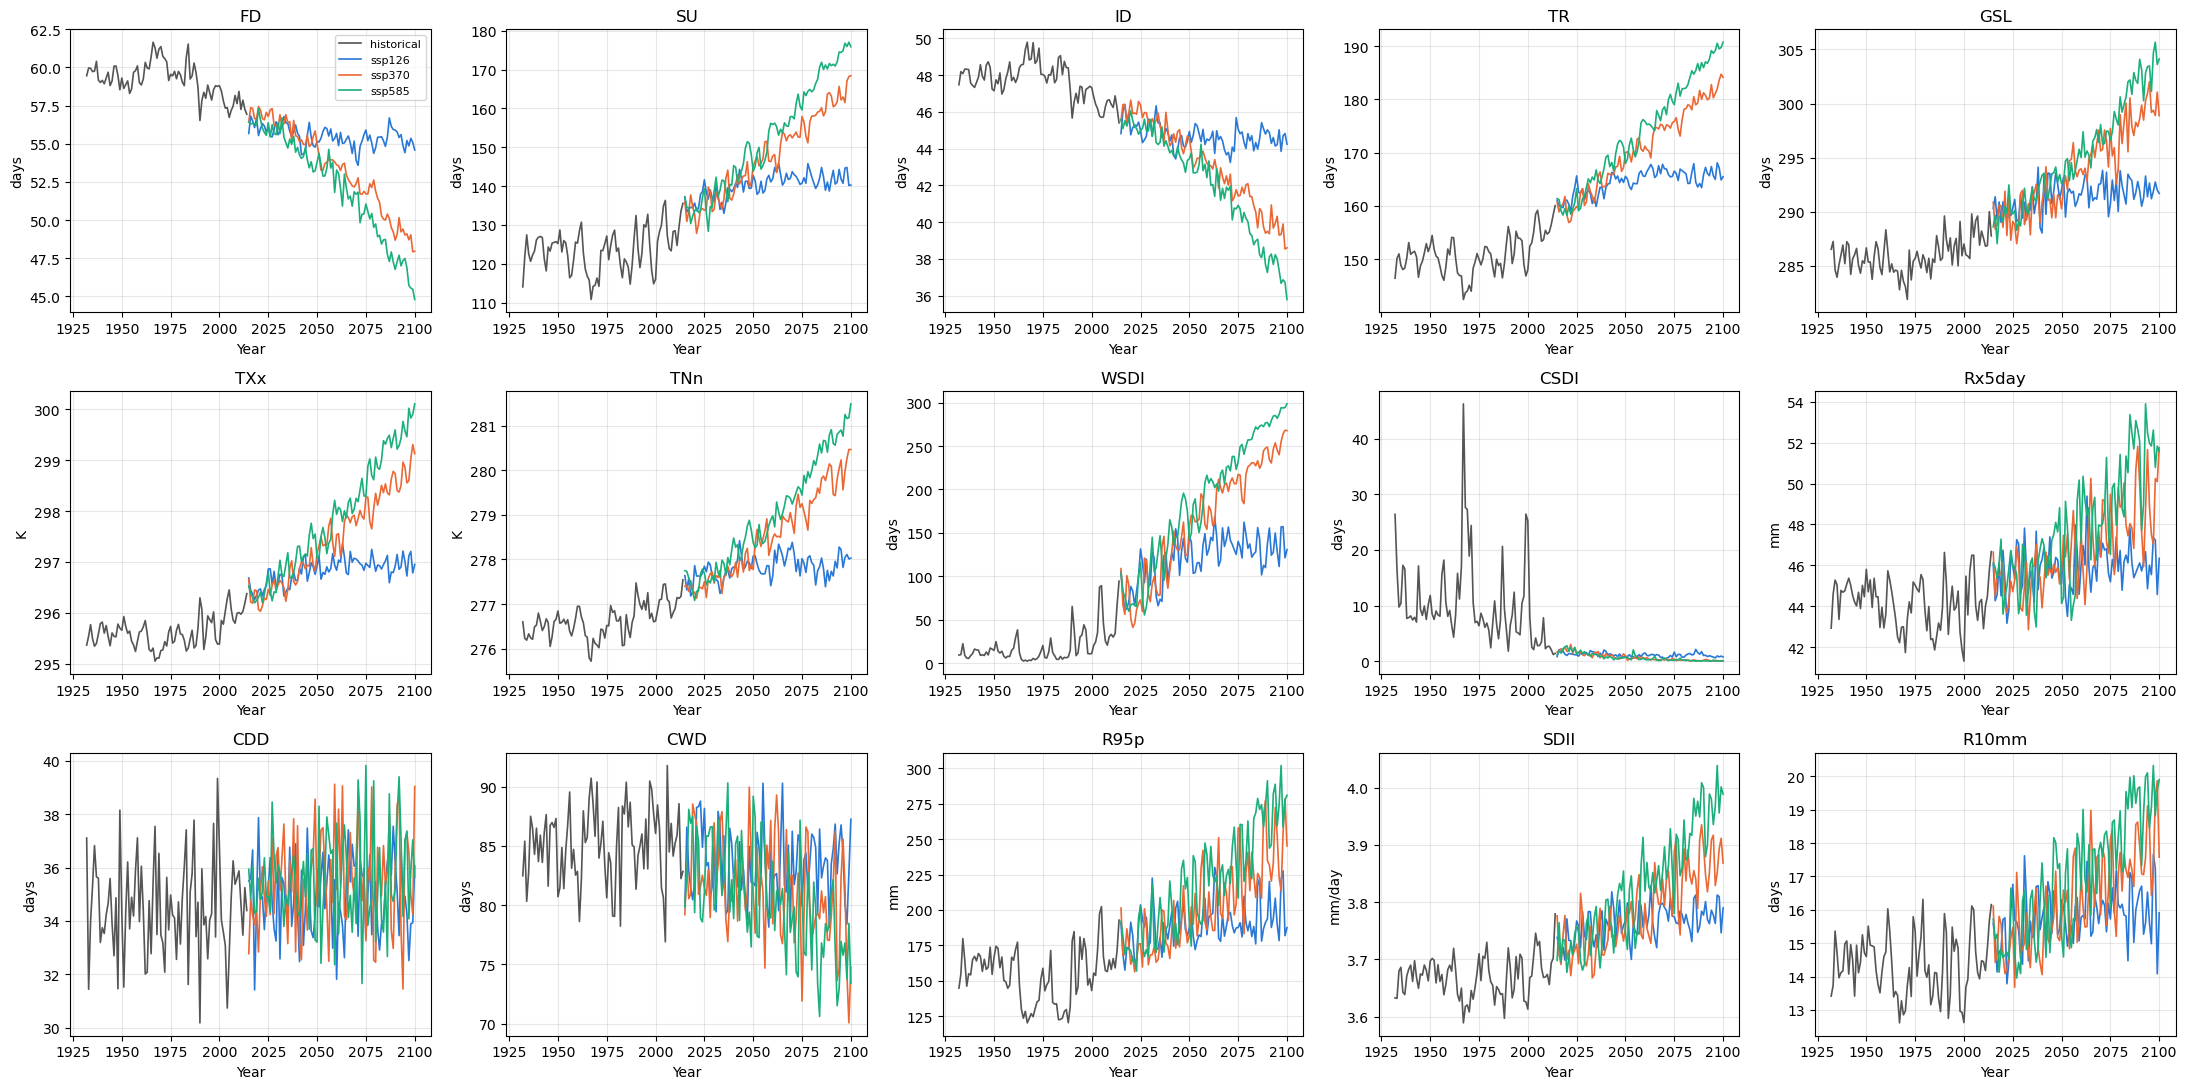

In [27]:
# Global mean time series for all 15
fig, axes = plt.subplots(3, 5, figsize=(22, 11))
for ax, name in zip(axes.flat, SELECTED_INDICES):
    for s, idx in indices.items():
        y = global_mean(to_yearly_index(name, idx[name]))
        ax.plot(y.year, y, color=COLORS[s], linewidth=1.2, label=s)
    ax.set_title(name)
    ax.set_ylabel(UNITS[name])
    ax.set_xlabel("Year")
    ax.grid(alpha=0.3)
axes.flat[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

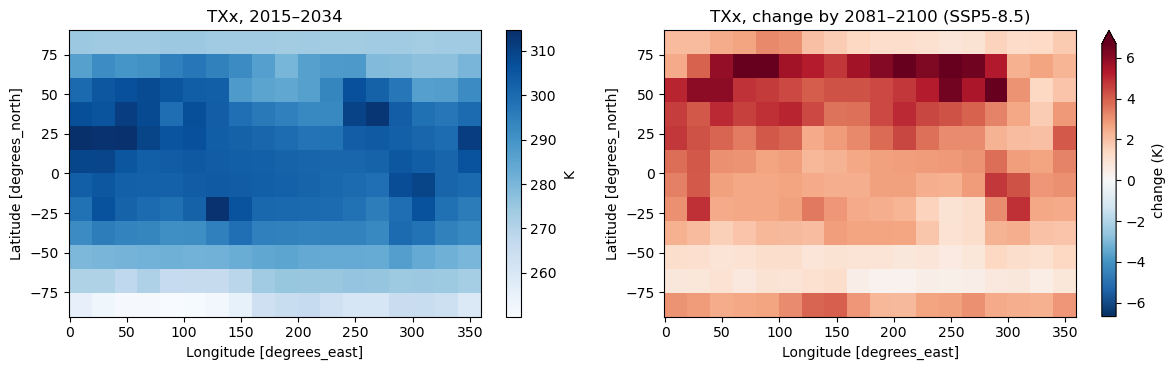

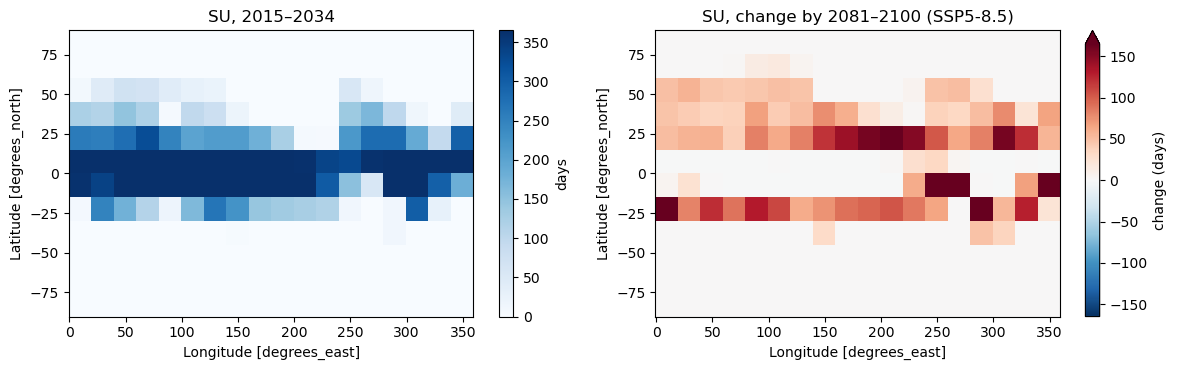

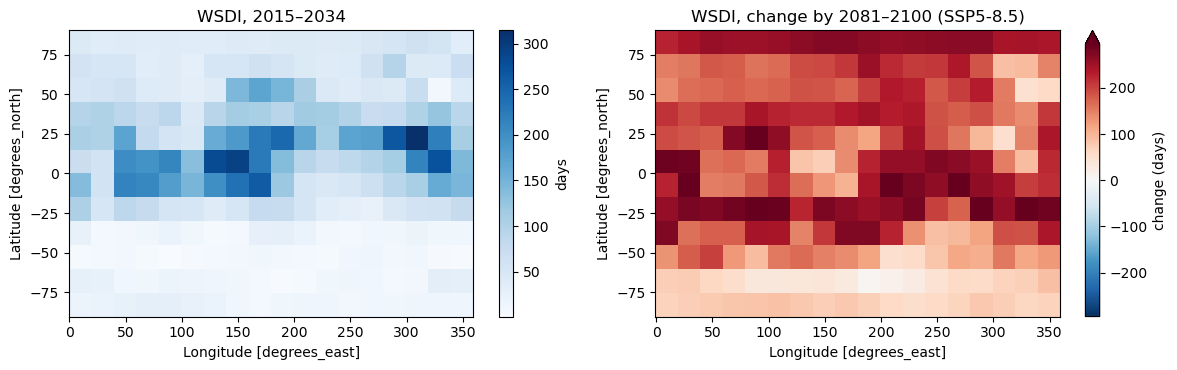

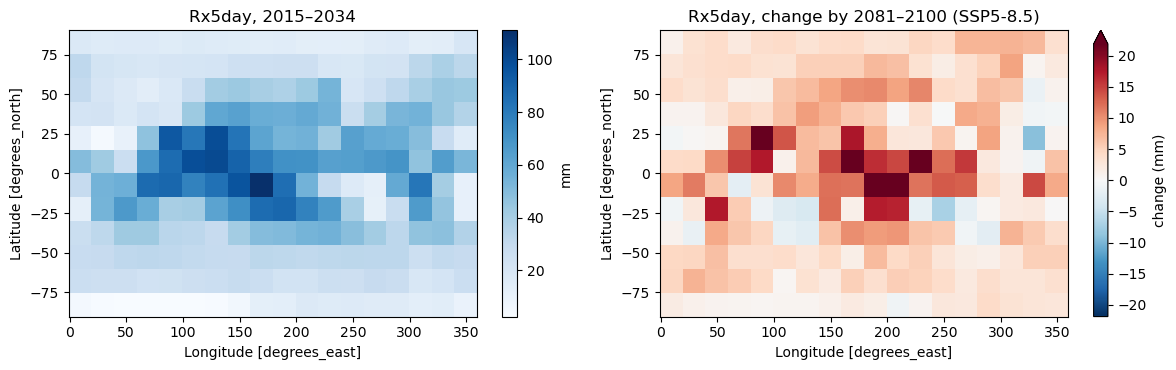

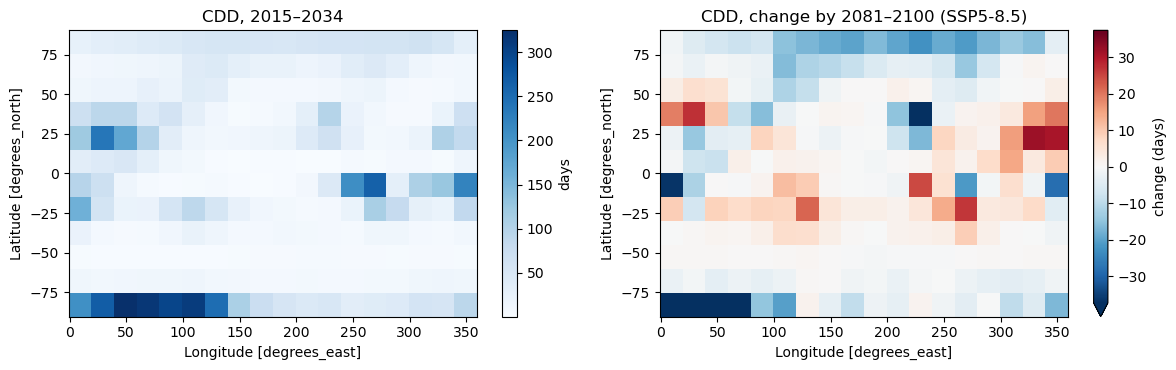

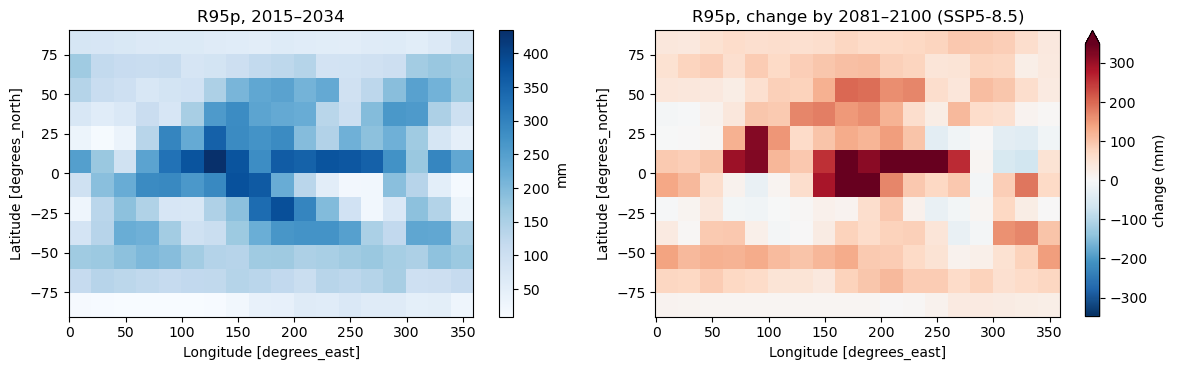

In [29]:
# Maps: early climate and end-of-century change (SSP5-8.5)
def period_mean(name, scenario, start, end):
    return to_yearly_index(name, indices[scenario][name]).sel(year=slice(start, end)).mean("year")

for name in ["TXx", "SU", "WSDI", "Rx5day", "CDD", "R95p"]:
    early = period_mean(name, "ssp585", 2015, 2034)
    late  = period_mean(name, "ssp585", 2081, 2100)

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    early.plot(ax=axes[0], x="lon", y="lat", cmap="Blues", cbar_kwargs={"label": UNITS[name]})
    axes[0].set_title(f"{name}, 2015–2034")
    (late - early).plot(ax=axes[1], x="lon", y="lat", cmap="RdBu_r", center=0, robust=True,
                        cbar_kwargs={"label": f"change ({UNITS[name]})"})
    axes[1].set_title(f"{name}, change by 2081–2100 (SSP5-8.5)")
    plt.tight_layout()
    plt.show()

#### Wich indices are hard to predict?

In [30]:
# Signal vs noise, and cells with no variability
def signal_to_noise(name, scenario="ssp585"):
    y = to_yearly_index(name, indices[scenario][name]).astype("float64")
    signal = y.sel(year=slice(2081, 2100)).mean("year") - y.sel(year=slice(2015, 2034)).mean("year")
    noise = (y - y.rolling(year=21, center=True, min_periods=11).mean()).std("year")   # year-to-year wiggle
    snr = abs(signal) / noise.where(noise > 0)
    no_variability = (y.std("year") <= 1e-3).mean()          # e.g. FD = 0 every year in the tropics
    return {"index": name,
            "median signal/noise": float(snr.median()),
            "% cells with no variability": 100 * float(no_variability)}

snr = pd.DataFrame([signal_to_noise(n) for n in SELECTED_INDICES]).set_index("index")
snr.sort_values("median signal/noise").round(2)

,median signal/noise,% cells with no variability
index,,
CDD,0.45,0.00
CWD,0.48,0.00
GSL,0.50,25.93
R10mm,0.69,7.41
CSDI,0.70,20.37
Rx5day,0.82,0.00
SDII,0.84,0.00
R95p,1.35,0.00
FD,2.51,46.30


#### How sensitive are the indices to errors in the daily fields?

In [31]:
# Two experiments:
daily = load_daily("ssp585")
reference = indices["ssp585"]

In [33]:
 # Experiment A: all temperatures 0.5 K too warm (a small model bias)
warm = daily.copy()
for v in ["tas", "tasmax", "tasmin"]:
    warm[v] = daily[v] + 0.5
    warm[v].attrs = daily[v].attrs          # keep units; arithmetic drops attributes

# Experiment B: precipitation smoothed with a 3-day running mean (same total, less spiky)
smooth = daily.copy()
smooth["pr"] = daily["pr"].rolling(time=3, center=True, min_periods=1).mean()
smooth["pr"].attrs = daily["pr"].attrs

experiments = {"+0.5 K temperature": compute_indices(warm, baseline),
                "3-day smoothed pr": compute_indices(smooth, baseline)}

In [34]:
rows = []
for name in SELECTED_INDICES:
    ref = float(global_mean(to_yearly_index(name, reference[name])).mean())
    row = {"index": name, "units": UNITS[name], "reference": ref}
    for label, result in experiments.items():
        val = float(global_mean(to_yearly_index(name, result[name])).mean())
        row[f"{label}: change"] = val - ref
        row[f"{label}: %"] = 100 * (val - ref) / ref if ref else np.nan
    rows.append(row)

sensitivity = pd.DataFrame(rows).set_index("index")
sensitivity.round(2)

,units,reference,+0.5 K temperature: change,+0.5 K temperature: %,3-day smoothed pr: change,3-day smoothed pr: %
index,,,,,,
FD,days,52.24,-1.89,-3.62,0.00,0.00
SU,days,152.65,6.45,4.22,0.00,0.00
ID,days,42.08,-1.82,-4.34,0.00,0.00
TR,days,173.81,4.57,2.63,0.00,0.00
GSL,days,295.44,3.39,1.15,0.00,0.00
TXx,K,297.86,0.50,0.17,0.00,0.00
TNn,K,278.99,0.50,0.18,0.00,0.00
WSDI,days,186.93,39.73,21.25,0.00,0.00
CSDI,days,0.69,-0.45,-65.78,0.00,0.00
